# Imports

In [1]:
import os
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import pyepo
import numpy as np
import time
import copy
from sklearn.model_selection import train_test_split
import seaborn as sns
import matplotlib.pyplot as plt

# Import all optimization models including the new AP and Flow relaxations
from nlp_spo_plus.optimization.cvrp import (
    cvrpMTZModel, cvrpMTZModelRel, 
    cvrpDFJModel, cvrpDFJModelRel, 
    cvrpAPModelRel, cvrpFlowModelRel
)
from nlp_spo_plus.data.cvrp_num import genData

# Configuration

In [3]:
MODEL_DIR = os.path.join("../..", "models/numerical_dfl")
os.makedirs(MODEL_DIR, exist_ok=True)

In [3]:
num_data = 2500       # Number of examples
num_features = 5     # Ex: Weather, Day of week, etc
num_clients = 10     # Number of clients to visit
num_vehicules = 3 
poly_degree = 4      # The True relation between x and c is polynomial of degree 4 (Misspecification)

# Data Generation

In [4]:
x, c, demands, capacity = genData(num_data=num_data, num_features=5, deg=poly_degree, num_clients=num_clients, num_vehicules=num_vehicules)
x_temp, x_test, c_temp, c_test = train_test_split(
    x, c, test_size=0.2, shuffle=True, random_state=42
)

x_train, x_val, c_train, c_val = train_test_split(
    x_temp, c_temp, test_size=0.25, shuffle=True, random_state=42
)

In [5]:
opt_mtz_model = cvrpMTZModel(num_nodes=num_clients+1, demands=demands, capacity=capacity, num_vehicles=num_vehicules)
dataset_train = pyepo.data.dataset.optDataset(model=opt_mtz_model, feats=x_train, costs=c_train)
dataset_val = pyepo.data.dataset.optDataset(model=opt_mtz_model, feats=x_val, costs=c_val)
dataset_test = pyepo.data.dataset.optDataset(model=opt_mtz_model, feats=x_test, costs=c_test)

loader_train = DataLoader(dataset_train, batch_size=32, shuffle=False)
loader_val = DataLoader(dataset_val, batch_size=32, shuffle=False)
loader_test = DataLoader(dataset_test, batch_size=32, shuffle=False)

Set parameter Username
Set parameter LicenseID to value 2866457
Academic license - for non-commercial use only - expires 2027-09-22


100%|██████████| 500/500 [01:37<00:00,  5.15it/s]


# Models Definition

## Linear Models (Model Misspecification)

- The relation between x and c is non linear (polynomial of degree 4), so we expect that the linear model would be incapable of explaining the data, and in this case we expect to see a considerable difference between SPO+ model and MSE model considering SPO loss ( SPO+ Model considerably better !)

In [6]:
class LinearRegression(nn.Module):
    def __init__(self, num_features, num_edges):
        super().__init__()
        self.num_features = num_features
        self.num_edges = num_edges
        self.linear = nn.Linear(in_features=num_features, out_features=num_edges)
    def forward(self, x):
        return self.linear(x)

In [7]:
num_edges = opt_mtz_model.num_cost
# Linear Models Instantiation
linear_model_mse = LinearRegression(num_features=num_features, num_edges=num_edges)
linear_model_spo_mtz_rel = LinearRegression(num_features=num_features, num_edges=num_edges)
linear_model_spo_dfj_rel = LinearRegression(num_features=num_features, num_edges=num_edges)
linear_model_spo_ap_rel = LinearRegression(num_features=num_features, num_edges=num_edges)
linear_model_spo_flow_rel = LinearRegression(num_features=num_features, num_edges=num_edges)

# Initialize with same weights for fair comparison
linear_model_spo_mtz_rel.load_state_dict(linear_model_mse.state_dict())
linear_model_spo_dfj_rel.load_state_dict(linear_model_mse.state_dict())
linear_model_spo_ap_rel.load_state_dict(linear_model_mse.state_dict())
linear_model_spo_flow_rel.load_state_dict(linear_model_mse.state_dict())

<All keys matched successfully>

## MLP Models (A Richer Hypothesis Space)

- Here we expect the model to be able to explain the relation between x and c, and therefore both models MSE and SPO+ will have small SPO losses.

In [8]:
class SimpleMLP(nn.Module):
    def __init__(self, num_features, num_edges, hidden_dim=64):
        super().__init__()
        self.num_features = num_features
        self.num_edges = num_edges
        self.hidden_dim = hidden_dim
        self.network = nn.Sequential(
            nn.Linear(num_features, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, num_edges)
        )
    def forward(self, x):
        return self.network(x)

In [9]:
# MLP Models Instantiation
mlp_model_mse = SimpleMLP(num_features=num_features, num_edges=num_edges)
mlp_model_spo_mtz_rel = SimpleMLP(num_features=num_features, num_edges=num_edges)
mlp_model_spo_dfj_rel = SimpleMLP(num_features=num_features, num_edges=num_edges)
mlp_model_spo_ap_rel = SimpleMLP(num_features=num_features, num_edges=num_edges)
mlp_model_spo_flow_rel = SimpleMLP(num_features=num_features, num_edges=num_edges)

# Initialize with same weights for fair comparison
mlp_model_spo_mtz_rel.load_state_dict(mlp_model_mse.state_dict())
mlp_model_spo_dfj_rel.load_state_dict(mlp_model_mse.state_dict())
mlp_model_spo_ap_rel.load_state_dict(mlp_model_mse.state_dict())
mlp_model_spo_flow_rel.load_state_dict(mlp_model_mse.state_dict())

<All keys matched successfully>

# Models Training

In [10]:
# Instantiate Optimization Models for training
opt_mtz_model_rel = cvrpMTZModelRel(num_nodes=num_clients+1, demands=demands, capacity=capacity, num_vehicles=num_vehicules)
opt_dfj_model_rel = cvrpDFJModelRel(num_nodes=num_clients+1, demands=demands, capacity=capacity, num_vehicles=num_vehicules)
opt_ap_model_rel = cvrpAPModelRel(num_nodes=num_clients+1, demands=demands, capacity=capacity, num_vehicles=num_vehicules)
opt_flow_model_rel = cvrpFlowModelRel(num_nodes=num_clients+1, demands=demands, capacity=capacity, num_vehicles=num_vehicules)

In [11]:
def train_model(model, train_loader, val_loader, optmodel, num_epochs, model_name, is_spo=False, patience=10, min_delta=1e-4):
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)
    if is_spo:
        criterion = pyepo.func.SPOPlus(optmodel=optmodel, processes=1)
    else:
        criterion = nn.MSELoss()

    best_val_loss = float('inf')
    patience_counter = 0
    best_model_wts = copy.deepcopy(model.state_dict())

    # start timer
    start_time = time.time()

    for epoch in range(num_epochs):
        # training phase
        model.train()
        epoch_train_loss = 0
        for data in train_loader:
            x, c, w, z = data
            optimizer.zero_grad()
            c_hat = model(x)

            if is_spo:
                loss = criterion(c_hat, c, w, z)
            else:
                loss = criterion(c_hat, c)
            loss.backward()
            optimizer.step()
            epoch_train_loss += loss.item()

        avg_train_loss = epoch_train_loss / len(train_loader)

        # validation phase
        model.eval()
        epoch_val_loss = 0
        with torch.no_grad():
            for data in val_loader:
                x, c, w, z = data
                c_hat = model(x)
                if is_spo:
                    val_loss = criterion(c_hat, c, w, z)
                else:
                    val_loss = criterion(c_hat, c)
                epoch_val_loss += val_loss.item()

        avg_val_loss = epoch_val_loss / len(val_loader)

        if (epoch + 1) % 5 == 0:
            mode = "SPO+" if is_spo else "MSE"
            print(f"[{mode}] Epoch {epoch+1}/{num_epochs} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")

        # early stopping
        if avg_val_loss < best_val_loss - min_delta:
            best_val_loss = avg_val_loss
            patience_counter = 0
            best_model_wts = copy.deepcopy(model.state_dict())
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"Early stopping triggered at epoch {epoch+1}. Restoring best model weights (Val Loss: {best_val_loss:.4f}).")
                break

    # stop timer and calculate duration
    end_time = time.time()
    training_time = end_time - start_time
    
    print(f"Total training time: {training_time:.2f} seconds.")

    # restore best model weights
    model.load_state_dict(best_model_wts)
    
    # Save the model to disk
    save_path = os.path.join(MODEL_DIR, model_name)
    torch.save(best_model_wts, save_path)
    print(f"Model saved successfully to {save_path}\n")
    
    return model, training_time

## Linear Models

In [12]:
# --- Training Linear Models ---
print("--- Training Linear Model (MSE) ---")
linear_model_mse, tt_lin_mse = train_model(linear_model_mse, loader_train, loader_val, opt_dfj_model_rel, 200, "linear_mse.pth", is_spo=False)

print("--- Training Linear Model (SPO+ MTZ) ---")
linear_model_spo_mtz_rel, tt_lin_mtz = train_model(linear_model_spo_mtz_rel, loader_train, loader_val, opt_mtz_model_rel, 200, "linear_spo_mtz.pth", is_spo=True)

print("--- Training Linear Model (SPO+ DFJ) ---")
linear_model_spo_dfj_rel, tt_lin_dfj = train_model(linear_model_spo_dfj_rel, loader_train, loader_val, opt_dfj_model_rel, 200, "linear_spo_dfj.pth", is_spo=True)

print("--- Training Linear Model (SPO+ AP) ---")
linear_model_spo_ap_rel, tt_lin_ap = train_model(linear_model_spo_ap_rel, loader_train, loader_val, opt_ap_model_rel, 200, "linear_spo_ap.pth", is_spo=True)

print("--- Training Linear Model (SPO+ Flow) ---")
linear_model_spo_flow_rel, tt_lin_flow = train_model(linear_model_spo_flow_rel, loader_train, loader_val, opt_flow_model_rel, 200, "linear_spo_flow.pth", is_spo=True)

--- Training Linear Model (MSE) ---
[MSE] Epoch 5/200 | Train Loss: 40.3464 | Val Loss: 34.6047
[MSE] Epoch 10/200 | Train Loss: 21.8036 | Val Loss: 18.3269
[MSE] Epoch 15/200 | Train Loss: 14.0126 | Val Loss: 11.6893
[MSE] Epoch 20/200 | Train Loss: 10.9799 | Val Loss: 9.2300
[MSE] Epoch 25/200 | Train Loss: 9.8927 | Val Loss: 8.4213
[MSE] Epoch 30/200 | Train Loss: 9.5291 | Val Loss: 8.1924
[MSE] Epoch 35/200 | Train Loss: 9.4120 | Val Loss: 8.1416
[MSE] Epoch 40/200 | Train Loss: 9.3746 | Val Loss: 8.1375
[MSE] Epoch 45/200 | Train Loss: 9.3629 | Val Loss: 8.1426
Early stopping triggered at epoch 48. Restoring best model weights (Val Loss: 8.1370).
Total training time: 2.55 seconds.
Model saved successfully to ..\models\linear_mse.pth

--- Training Linear Model (SPO+ MTZ) ---
[SPO+] Epoch 5/200 | Train Loss: 24.4104 | Val Loss: 18.7622
[SPO+] Epoch 10/200 | Train Loss: 12.7102 | Val Loss: 10.5388
[SPO+] Epoch 15/200 | Train Loss: 10.0799 | Val Loss: 8.6942
[SPO+] Epoch 20/200 | Trai

## MLP Models

In [13]:
# --- Training MLP Models ---
print("--- Training MLP Model (MSE) ---")
mlp_model_mse, tt_mlp_mse = train_model(mlp_model_mse, loader_train, loader_val, opt_dfj_model_rel, 200, "mlp_mse.pth", is_spo=False)

print("--- Training MLP Model (SPO+ MTZ) ---")
mlp_model_spo_mtz_rel, tt_mlp_mtz = train_model(mlp_model_spo_mtz_rel, loader_train, loader_val, opt_mtz_model_rel, 200, "mlp_spo_mtz.pth", is_spo=True)

print("--- Training MLP Model (SPO+ DFJ) ---")
mlp_model_spo_dfj_rel, tt_mlp_dfj = train_model(mlp_model_spo_dfj_rel, loader_train, loader_val, opt_dfj_model_rel, 200, "mlp_spo_dfj.pth", is_spo=True)

print("--- Training MLP Model (SPO+ AP) ---")
mlp_model_spo_ap_rel, tt_mlp_ap = train_model(mlp_model_spo_ap_rel, loader_train, loader_val, opt_ap_model_rel, 200, "mlp_spo_ap.pth", is_spo=True)

print("--- Training MLP Model (SPO+ Flow) ---")
mlp_model_spo_flow_rel, tt_mlp_flow = train_model(mlp_model_spo_flow_rel, loader_train, loader_val, opt_flow_model_rel, 200, "mlp_spo_flow.pth", is_spo=True)

--- Training MLP Model (MSE) ---
[MSE] Epoch 5/200 | Train Loss: 3.2489 | Val Loss: 2.4075
[MSE] Epoch 10/200 | Train Loss: 1.2286 | Val Loss: 1.1748
[MSE] Epoch 15/200 | Train Loss: 0.9087 | Val Loss: 0.9625
[MSE] Epoch 20/200 | Train Loss: 0.7264 | Val Loss: 0.8046
[MSE] Epoch 25/200 | Train Loss: 0.6147 | Val Loss: 0.6989
[MSE] Epoch 30/200 | Train Loss: 0.5384 | Val Loss: 0.6253
[MSE] Epoch 35/200 | Train Loss: 0.4860 | Val Loss: 0.5809
[MSE] Epoch 40/200 | Train Loss: 0.4483 | Val Loss: 0.5515
[MSE] Epoch 45/200 | Train Loss: 0.4131 | Val Loss: 0.5272
[MSE] Epoch 50/200 | Train Loss: 0.3830 | Val Loss: 0.5053
[MSE] Epoch 55/200 | Train Loss: 0.3567 | Val Loss: 0.4853
[MSE] Epoch 60/200 | Train Loss: 0.3345 | Val Loss: 0.4661
[MSE] Epoch 65/200 | Train Loss: 0.3173 | Val Loss: 0.4511
[MSE] Epoch 70/200 | Train Loss: 0.3034 | Val Loss: 0.4368
[MSE] Epoch 75/200 | Train Loss: 0.2923 | Val Loss: 0.4242
[MSE] Epoch 80/200 | Train Loss: 0.2850 | Val Loss: 0.4164
[MSE] Epoch 85/200 | Tra

# Comparing Losses

## Linear Models

In [14]:
mse_loss = nn.MSELoss()
with torch.no_grad():
    x_test_ts = torch.FloatTensor(x_test)
    c_test_ts = torch.FloatTensor(c_test)
    mse_lin_mse = mse_loss(linear_model_mse(x_test_ts), c_test_ts)
    mse_lin_mtz = mse_loss(linear_model_spo_mtz_rel(x_test_ts), c_test_ts)
    mse_lin_dfj = mse_loss(linear_model_spo_dfj_rel(x_test_ts), c_test_ts)
    mse_lin_ap  = mse_loss(linear_model_spo_ap_rel(x_test_ts), c_test_ts)
    mse_lin_flow = mse_loss(linear_model_spo_flow_rel(x_test_ts), c_test_ts)

print("Linear Models - MSE Error:")
print(f" - MSE baseline : {mse_lin_mse:.4f}")
print(f" - SPO+ (MTZ)   : {mse_lin_mtz:.4f}")
print(f" - SPO+ (DFJ)   : {mse_lin_dfj:.4f}")
print(f" - SPO+ (AP)    : {mse_lin_ap:.4f}")
print(f" - SPO+ (Flow)  : {mse_lin_flow:.4f}\n")

Linear Models - MSE Error:
 - MSE baseline : 11.4116
 - SPO+ (MTZ)   : 67.5722
 - SPO+ (DFJ)   : 67.3049
 - SPO+ (AP)    : 68.1332
 - SPO+ (Flow)  : 67.3786



In [15]:
regret_lin_mse = pyepo.metric.regret(linear_model_mse, opt_mtz_model, loader_test)
regret_lin_mtz = pyepo.metric.regret(linear_model_spo_mtz_rel, opt_mtz_model, loader_test)
regret_lin_dfj = pyepo.metric.regret(linear_model_spo_dfj_rel, opt_mtz_model, loader_test)
regret_lin_ap  = pyepo.metric.regret(linear_model_spo_ap_rel, opt_mtz_model, loader_test)
regret_lin_flow = pyepo.metric.regret(linear_model_spo_flow_rel, opt_mtz_model, loader_test)

print("Linear Models - Decision Regret:")
print(f" - MSE baseline : {regret_lin_mse:.4f}")
print(f" - SPO+ (MTZ)   : {regret_lin_mtz:.4f}")
print(f" - SPO+ (DFJ)   : {regret_lin_dfj:.4f}")
print(f" - SPO+ (AP)    : {regret_lin_ap:.4f}")
print(f" - SPO+ (Flow)  : {regret_lin_flow:.4f}")

Linear Models - Decision Regret:
 - MSE baseline : 0.0736
 - SPO+ (MTZ)   : 0.0233
 - SPO+ (DFJ)   : 0.0179
 - SPO+ (AP)    : 0.0233
 - SPO+ (Flow)  : 0.0227


## MLP Models

In [16]:
# Load all MLP models from disk before evaluation
mlp_model_mse.load_state_dict(torch.load(os.path.join(MODEL_DIR, "mlp_mse.pth"), weights_only=True))
mlp_model_spo_mtz_rel.load_state_dict(torch.load(os.path.join(MODEL_DIR, "mlp_spo_mtz.pth"), weights_only=True))
mlp_model_spo_dfj_rel.load_state_dict(torch.load(os.path.join(MODEL_DIR, "mlp_spo_dfj.pth"), weights_only=True))
mlp_model_spo_ap_rel.load_state_dict(torch.load(os.path.join(MODEL_DIR, "mlp_spo_ap.pth"), weights_only=True))
mlp_model_spo_flow_rel.load_state_dict(torch.load(os.path.join(MODEL_DIR, "mlp_spo_flow.pth"), weights_only=True))

mlp_model_mse.eval()
mlp_model_spo_mtz_rel.eval()
mlp_model_spo_dfj_rel.eval()
mlp_model_spo_ap_rel.eval()
mlp_model_spo_flow_rel.eval()

with torch.no_grad():
    mse_mlp_mse = mse_loss(mlp_model_mse(x_test_ts), c_test_ts)
    mse_mlp_mtz = mse_loss(mlp_model_spo_mtz_rel(x_test_ts), c_test_ts)
    mse_mlp_dfj = mse_loss(mlp_model_spo_dfj_rel(x_test_ts), c_test_ts)
    mse_mlp_ap  = mse_loss(mlp_model_spo_ap_rel(x_test_ts), c_test_ts)
    mse_mlp_flow = mse_loss(mlp_model_spo_flow_rel(x_test_ts), c_test_ts)

print("MLP Models - MSE Error:")
print(f" - MSE baseline : {mse_mlp_mse:.4f}")
print(f" - SPO+ (MTZ)   : {mse_mlp_mtz:.4f}")
print(f" - SPO+ (DFJ)   : {mse_mlp_dfj:.4f}")
print(f" - SPO+ (AP)    : {mse_mlp_ap:.4f}")
print(f" - SPO+ (Flow)  : {mse_mlp_flow:.4f}\n")

MLP Models - MSE Error:
 - MSE baseline : 0.5563
 - SPO+ (MTZ)   : 47.9467
 - SPO+ (DFJ)   : 50.4806
 - SPO+ (AP)    : 54.2150
 - SPO+ (Flow)  : 51.5829



In [17]:
regret_mlp_mse = pyepo.metric.regret(mlp_model_mse, opt_mtz_model, loader_test)
regret_mlp_mtz = pyepo.metric.regret(mlp_model_spo_mtz_rel, opt_mtz_model, loader_test)
regret_mlp_dfj = pyepo.metric.regret(mlp_model_spo_dfj_rel, opt_mtz_model, loader_test)
regret_mlp_ap  = pyepo.metric.regret(mlp_model_spo_ap_rel, opt_mtz_model, loader_test)
regret_mlp_flow = pyepo.metric.regret(mlp_model_spo_flow_rel, opt_mtz_model, loader_test)

print("MLP Models - Decision Regret:")
print(f" - MSE baseline : {regret_mlp_mse:.4f}")
print(f" - SPO+ (MTZ)   : {regret_mlp_mtz:.4f}")
print(f" - SPO+ (DFJ)   : {regret_mlp_dfj:.4f}")
print(f" - SPO+ (AP)    : {regret_mlp_ap:.4f}")
print(f" - SPO+ (Flow)  : {regret_mlp_flow:.4f}")

MLP Models - Decision Regret:
 - MSE baseline : 0.0188
 - SPO+ (MTZ)   : 0.0113
 - SPO+ (DFJ)   : 0.0116
 - SPO+ (AP)    : 0.0105
 - SPO+ (Flow)  : 0.0123


## Analysis

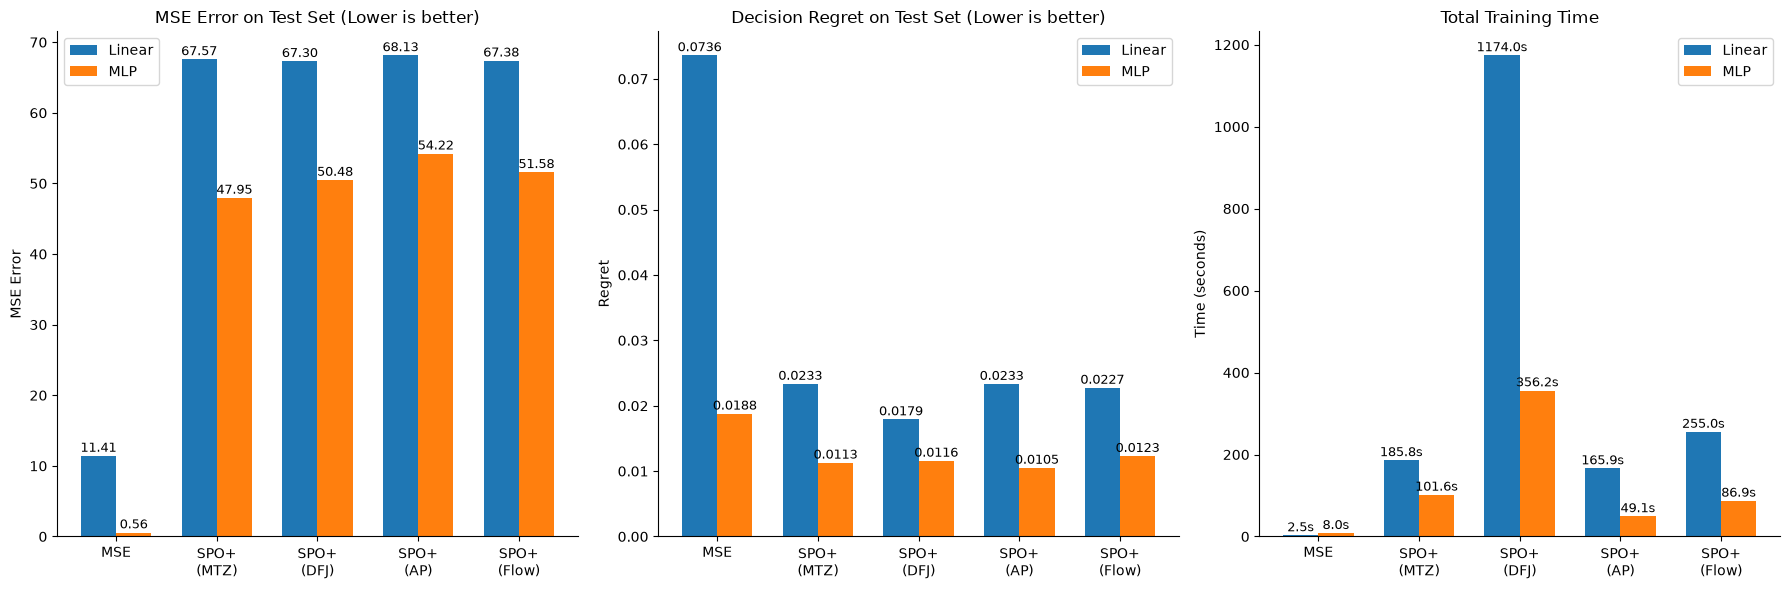

In [18]:
# ---------- Data Preparation ----------
labels = ["MSE", "SPO+\n(MTZ)", "SPO+\n(DFJ)", "SPO+\n(AP)", "SPO+\n(Flow)"]
x = np.arange(len(labels))
width = 0.35

# Linear Model Values
lin_mse_vals = [mse_lin_mse.item(), mse_lin_mtz.item(), mse_lin_dfj.item(), mse_lin_ap.item(), mse_lin_flow.item()]
lin_regret_vals = [regret_lin_mse, regret_lin_mtz, regret_lin_dfj, regret_lin_ap, regret_lin_flow]
lin_time_vals = [tt_lin_mse, tt_lin_mtz, tt_lin_dfj, tt_lin_ap, tt_lin_flow]

# MLP Model Values
mlp_mse_vals = [mse_mlp_mse.item(), mse_mlp_mtz.item(), mse_mlp_dfj.item(), mse_mlp_ap.item(), mse_mlp_flow.item()]
mlp_regret_vals = [regret_mlp_mse, regret_mlp_mtz, regret_mlp_dfj, regret_mlp_ap, regret_mlp_flow]
mlp_time_vals = [tt_mlp_mse, tt_mlp_mtz, tt_mlp_dfj, tt_mlp_ap, tt_mlp_flow]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# ---------- Plot 1: MSE Error ----------
ax1 = axes[0]
b1 = ax1.bar(x - width/2, lin_mse_vals, width, label="Linear", color="tab:blue")
b2 = ax1.bar(x + width/2, mlp_mse_vals, width, label="MLP", color="tab:orange")

for bars in (b1, b2):
    for b in bars:
        ax1.annotate(f"{b.get_height():.2f}",
                    xy=(b.get_x() + b.get_width()/2, b.get_height()),
                    xytext=(0, 3), textcoords="offset points",
                    ha="center", fontsize=9)

ax1.set_xticks(x)
ax1.set_xticklabels(labels)
ax1.set_ylabel("MSE Error")
ax1.set_title("MSE Error on Test Set (Lower is better)")
ax1.legend()
ax1.spines[["top", "right"]].set_visible(False)

# ---------- Plot 2: Decision Regret ----------
ax2 = axes[1]
b3 = ax2.bar(x - width/2, lin_regret_vals, width, label="Linear", color="tab:blue")
b4 = ax2.bar(x + width/2, mlp_regret_vals, width, label="MLP", color="tab:orange")

for bars in (b3, b4):
    for b in bars:
        ax2.annotate(f"{b.get_height():.4f}",
                    xy=(b.get_x() + b.get_width()/2, b.get_height()),
                    xytext=(0, 3), textcoords="offset points",
                    ha="center", fontsize=9)

ax2.set_xticks(x)
ax2.set_xticklabels(labels)
ax2.set_ylabel("Regret")
ax2.set_title("Decision Regret on Test Set (Lower is better)")
ax2.legend()
ax2.spines[["top", "right"]].set_visible(False)

# ---------- Plot 3: Training Time ----------
ax3 = axes[2]
b5 = ax3.bar(x - width/2, lin_time_vals, width, label="Linear", color="tab:blue")
b6 = ax3.bar(x + width/2, mlp_time_vals, width, label="MLP", color="tab:orange")

for bars in (b5, b6):
    for b in bars:
        ax3.annotate(f"{b.get_height():.1f}s",
                    xy=(b.get_x() + b.get_width()/2, b.get_height()),
                    xytext=(0, 3), textcoords="offset points",
                    ha="center", fontsize=9)

ax3.set_xticks(x)
ax3.set_xticklabels(labels)
ax3.set_ylabel("Time (seconds)")
ax3.set_title("Total Training Time")
ax3.legend()
ax3.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()